In [1]:
from collections import defaultdict
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform


In [2]:
rdms = np.load('../results/rdms_thresh_80/crossnobis_rdms.npz')
rdms.keys()

KeysView(NpzFile '../results/rdms_thresh_80/crossnobis_rdms.npz' with keys: rdms, subjects, rois, conditions)

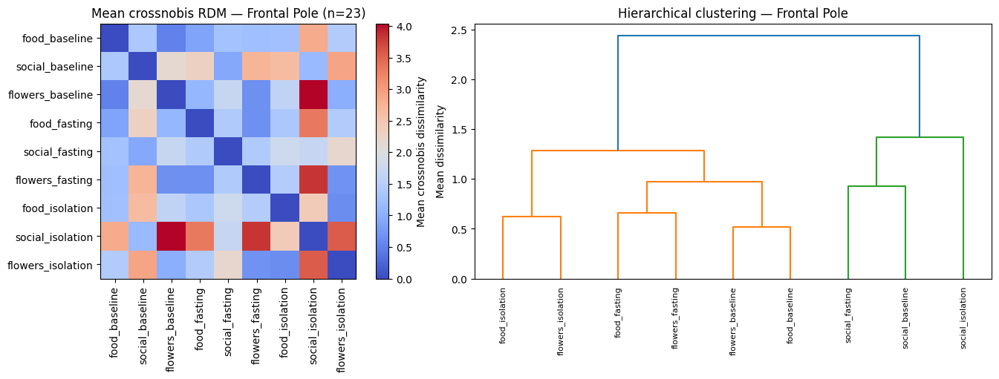

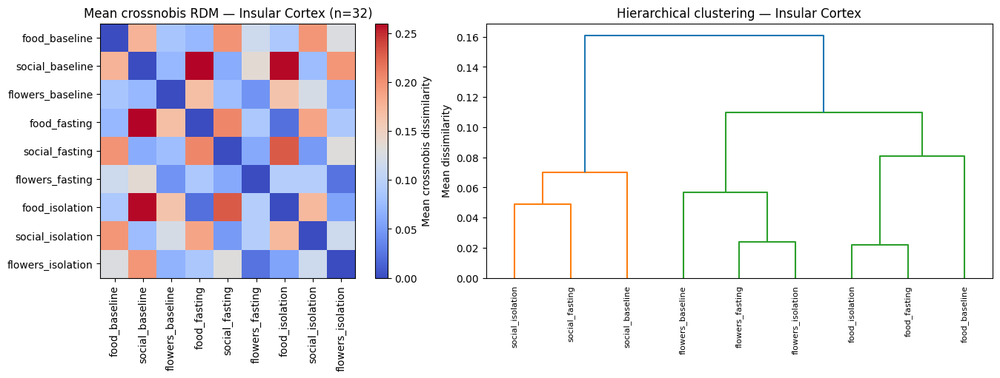

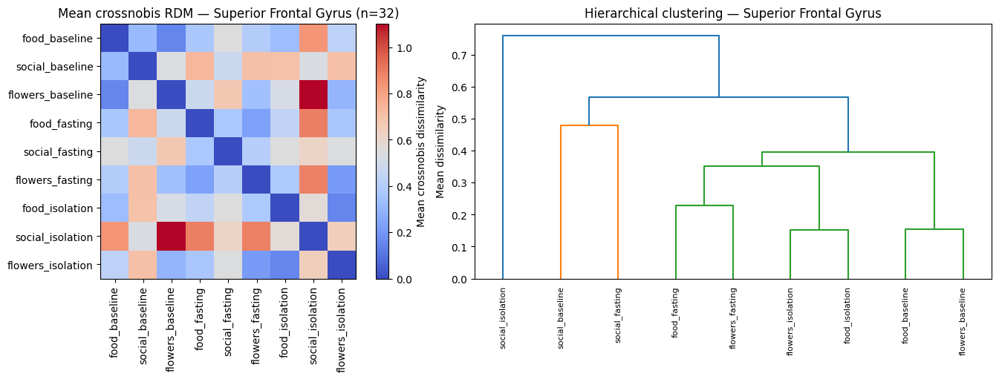

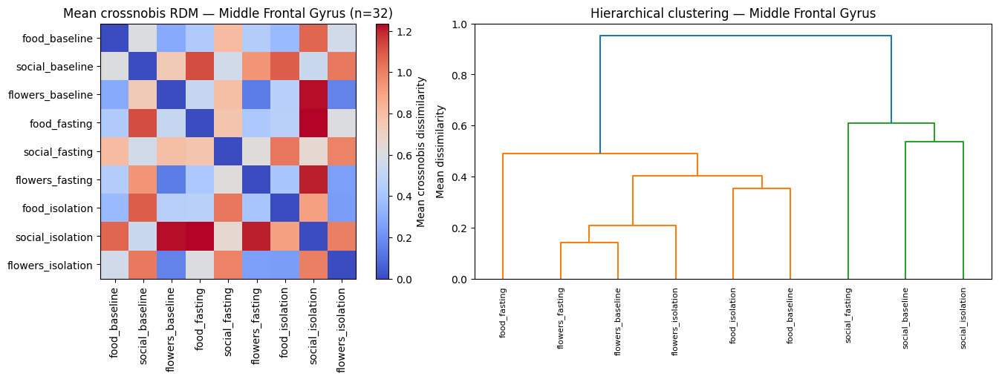

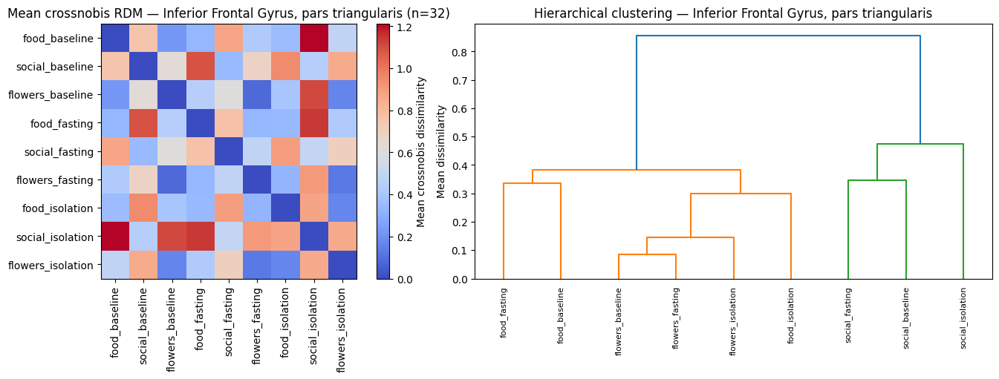

...

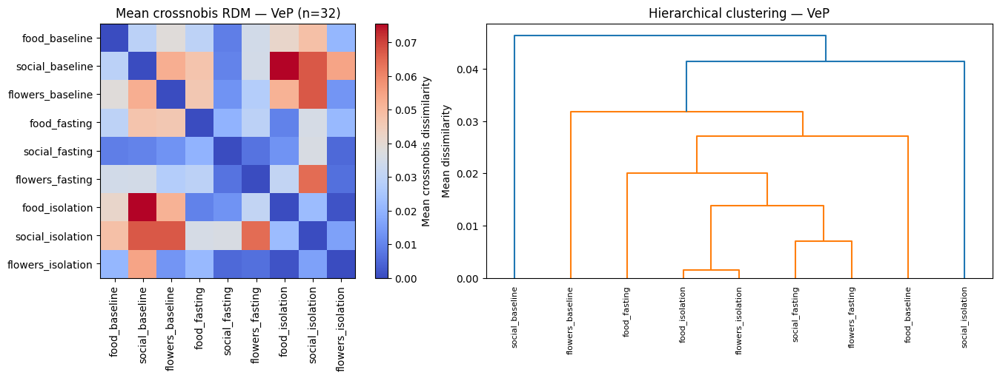

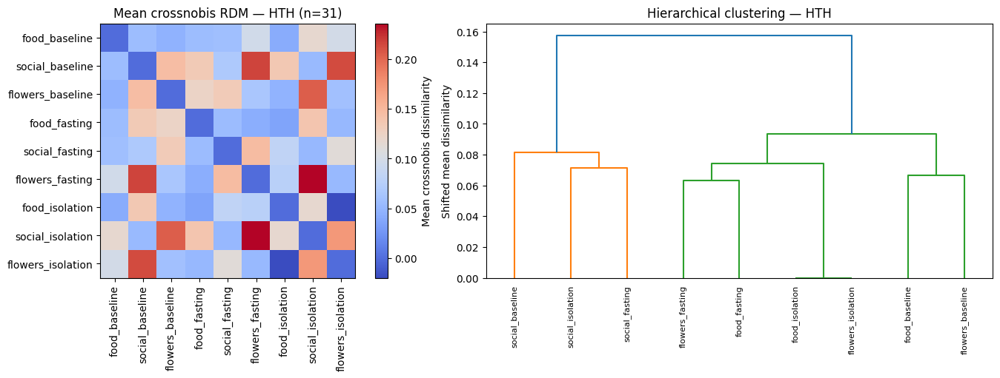

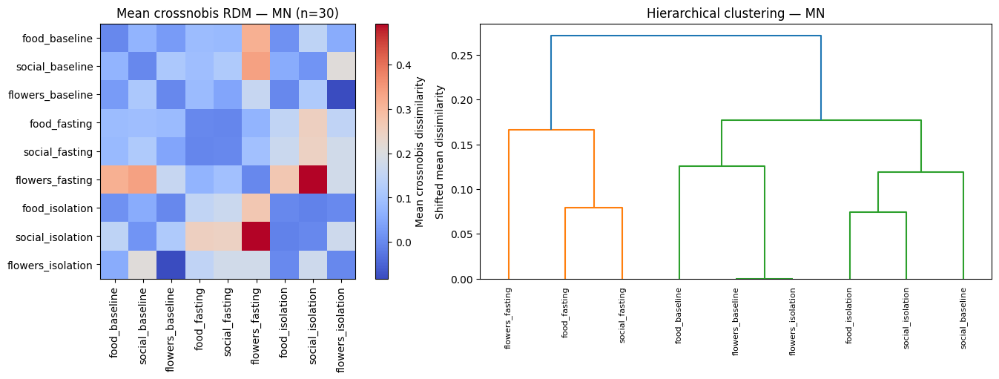

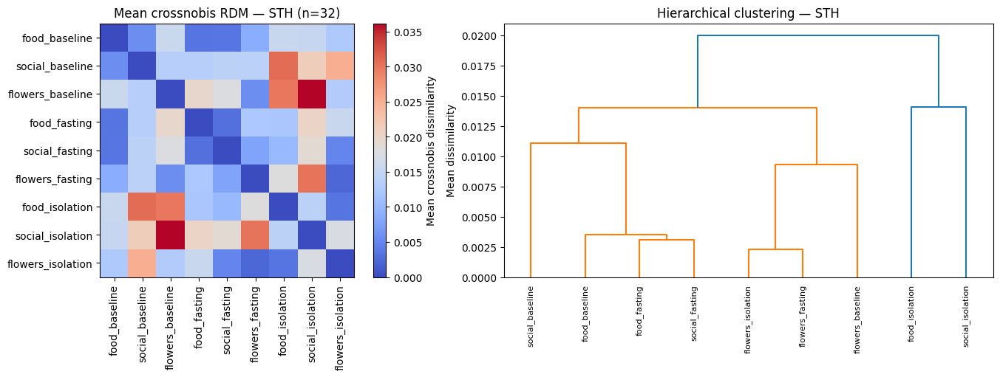

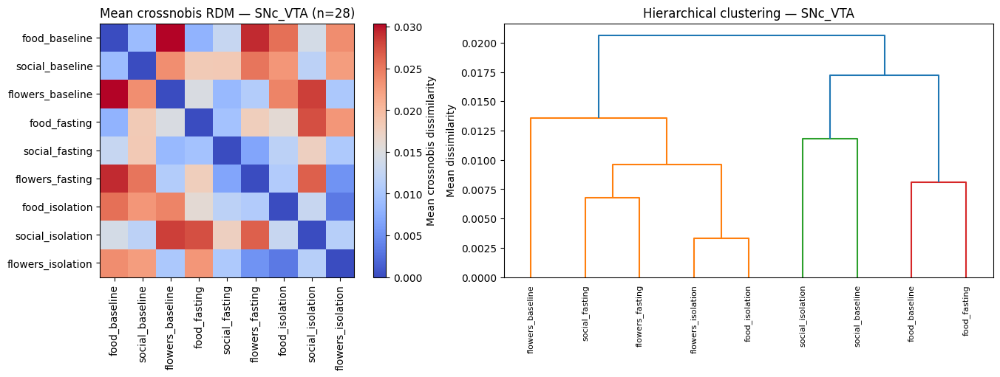

In [8]:


data = np.load("../results/rdms_thresh_80/crossnobis_rdms.npz")
all_rdms = data["rdms"]                      # [subject, roi, 9, 9]
subjects = list(data["subjects"])
rois = list(data["rois"])
contrasts = [str(c) for c in data["conditions"]]

n = len(contrasts)
upper = np.triu_indices(n, k=1)
MIN_PARTICIPANTS = 20

results = {}

for roi_idx, roi_file in enumerate(rois):
    roi = roi_file.removesuffix(".nii")

    # Keep participants who have an RDM for this ROI (missing ones are all-NaN)
    has_rdm = ~np.isnan(all_rdms[:, roi_idx]).all(axis=(1, 2))
    if has_rdm.sum() < MIN_PARTICIPANTS:
        continue

    subject_ids = [s for s, keep in zip(subjects, has_rdm) if keep]
    participant_rdms = all_rdms[has_rdm, roi_idx]          # [n_subjects, 9, 9]

    if not np.isfinite(participant_rdms).all():
        raise ValueError(f"Non-finite values in RDMs for {roi}")
    if not np.allclose(participant_rdms, participant_rdms.transpose(0, 2, 1), atol=1e-6):
        raise ValueError(f"Non-symmetric RDM found for {roi}")

    mean_rdm = participant_rdms.mean(axis=0)
    mean_rdm = (mean_rdm + mean_rdm.T) / 2
    np.fill_diagonal(mean_rdm, 0)

    # Crossnobis distances may be negative. Shift every off-diagonal
    # value equally so scipy's hierarchical clustering can use them.
    shift = max(0.0, -float(mean_rdm[upper].min()))
    clustering_rdm = mean_rdm.copy()
    clustering_rdm[upper] += shift
    clustering_rdm[(upper[1], upper[0])] += shift

    condensed = squareform(clustering_rdm, checks=True)
    tree = linkage(condensed, method="average", optimal_ordering=True)

    fig, (ax_rdm, ax_tree) = plt.subplots(
        1, 2, figsize=(14, 5),
        gridspec_kw={"width_ratios": [1, 1.3]},
        layout="constrained",
    )

    image = ax_rdm.imshow(mean_rdm, cmap="coolwarm")
    ax_rdm.set_xticks(range(n), contrasts, rotation=90)
    ax_rdm.set_yticks(range(n), contrasts)
    ax_rdm.set_title(f"Mean crossnobis RDM — {roi} (n={len(subject_ids)})")
    fig.colorbar(image, ax=ax_rdm, label="Mean crossnobis dissimilarity")

    dendrogram(tree, labels=contrasts, ax=ax_tree, leaf_rotation=90, leaf_font_size=8)
    ax_tree.set_title(f"Hierarchical clustering — {roi}")
    ax_tree.set_ylabel("Shifted mean dissimilarity" if shift else "Mean dissimilarity")

    plt.show()

    results[roi] = {
        "mean_rdm": pd.DataFrame(mean_rdm, index=contrasts, columns=contrasts),
        "linkage": tree,
        "subjects": subject_ids,
        "distance_shift": shift,
    }

In [11]:
loneliness_df = pd.read_csv(
    "../dataframes/SISO_behavioral_data.csv"
)
loneliness_df["subject"] = loneliness_df["ID"].apply(lambda x: x.replace("_", ""))
loneliness_df = loneliness_df[["subject", "Loneliness_Score"]]

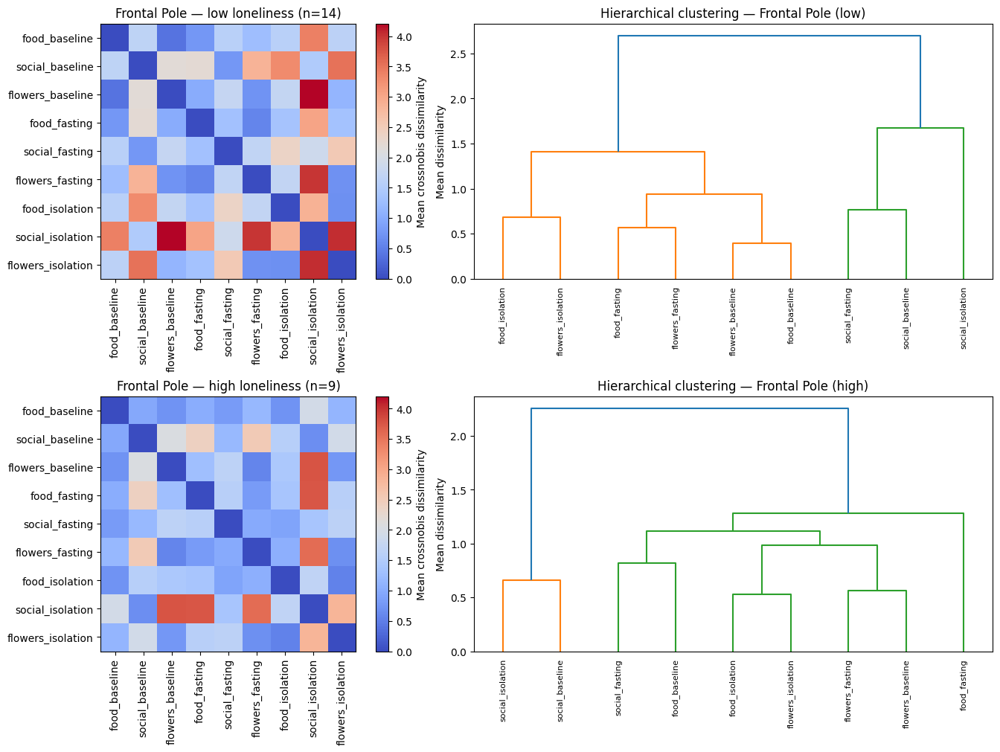

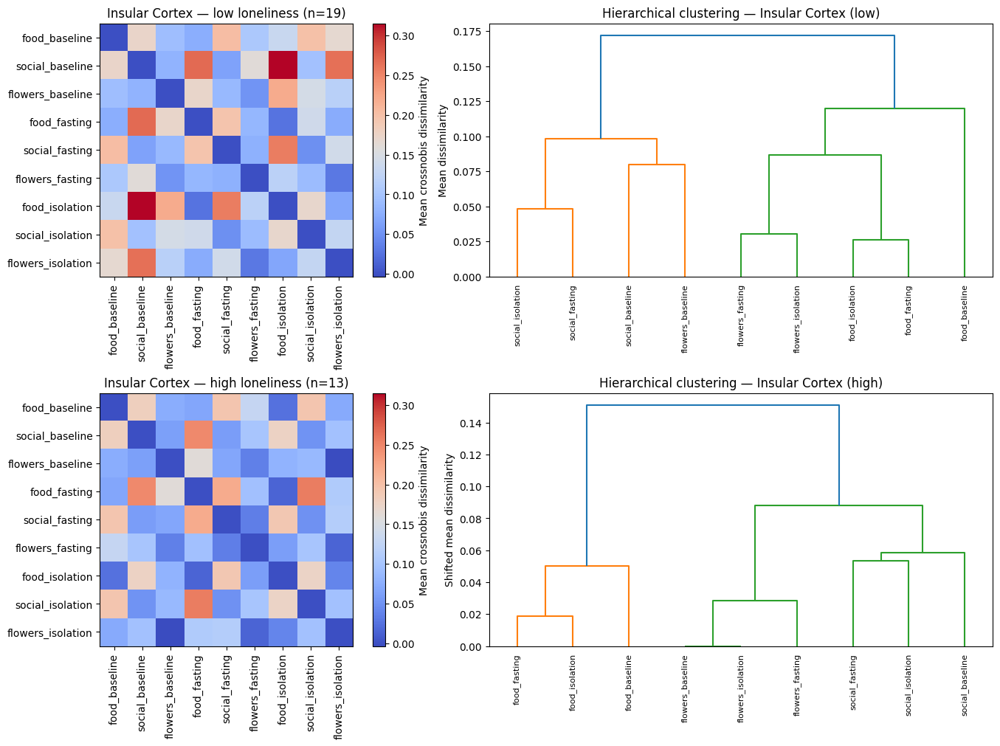

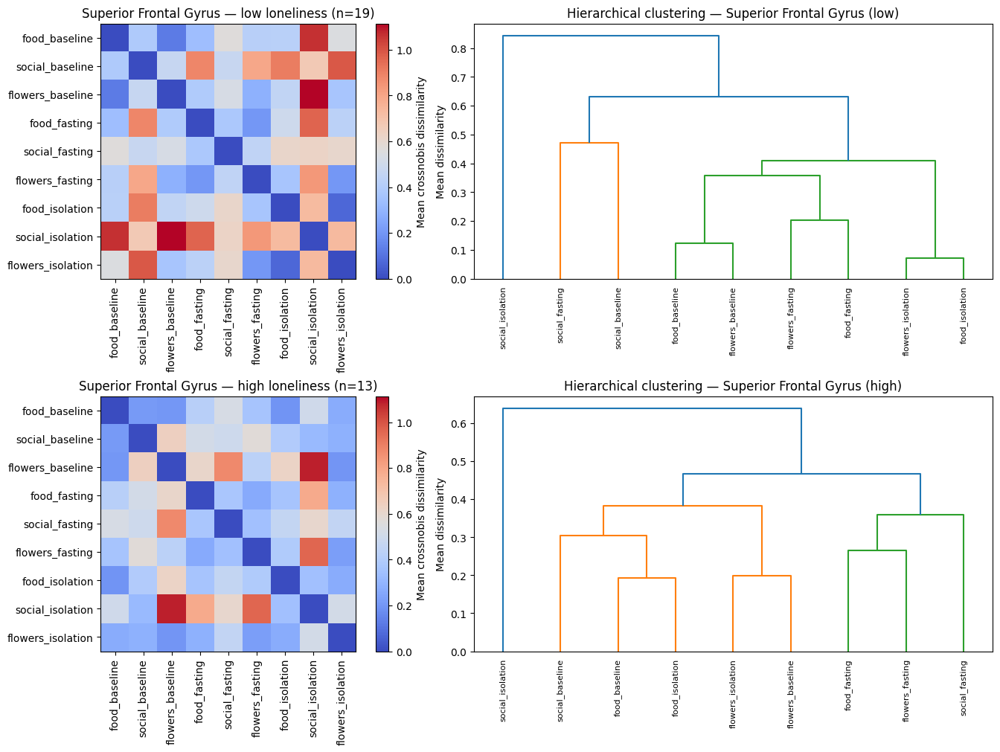

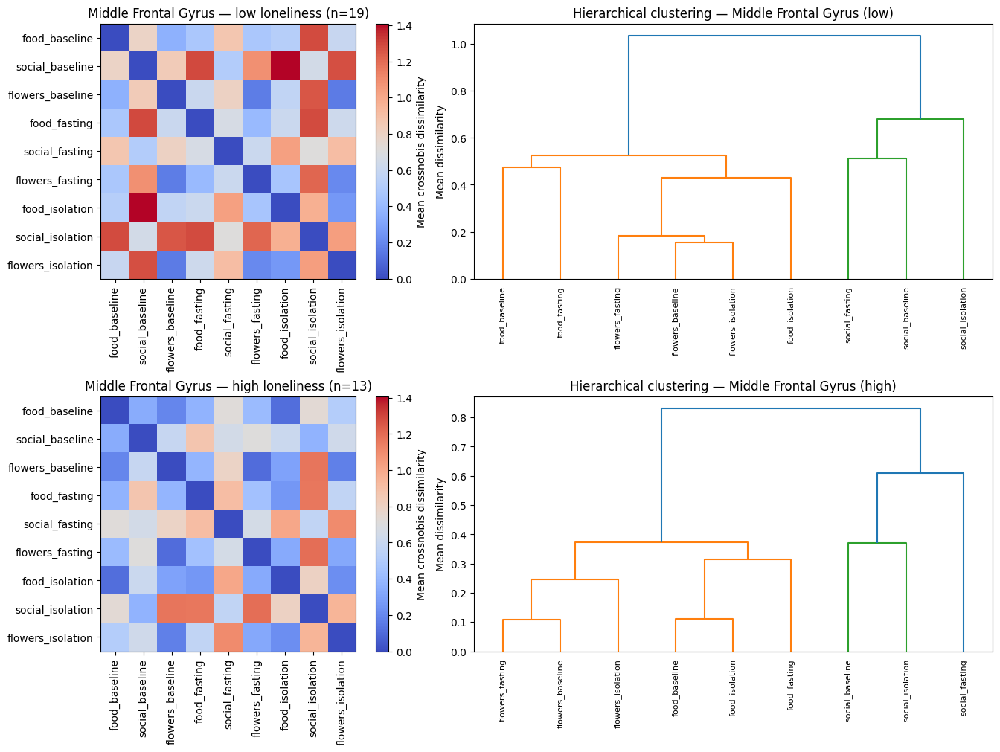

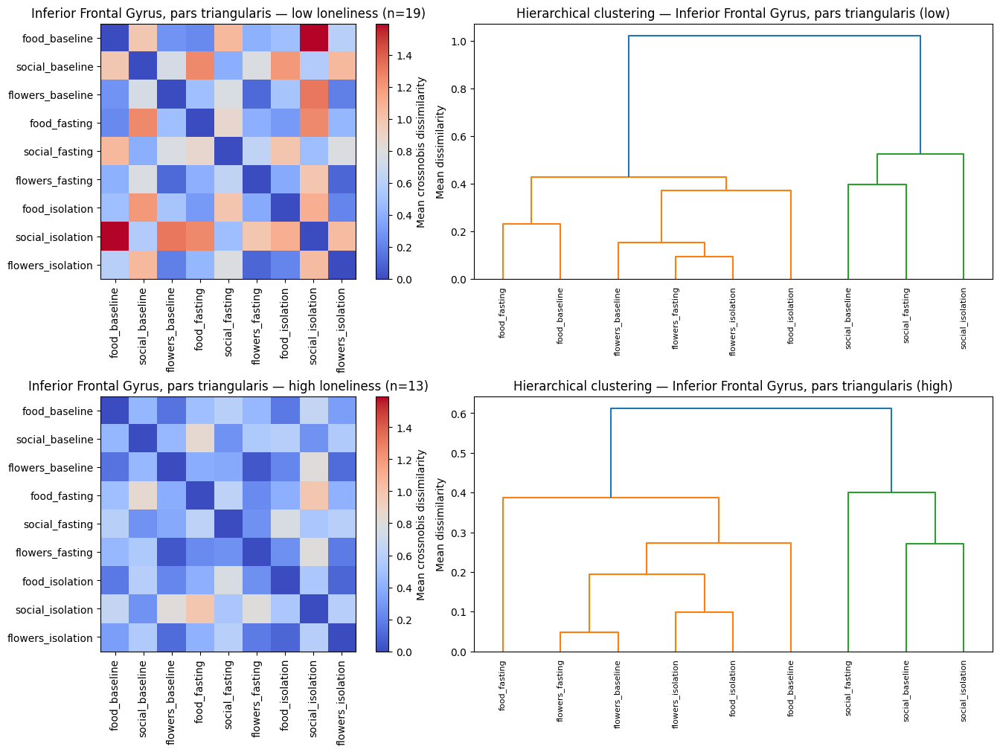

...

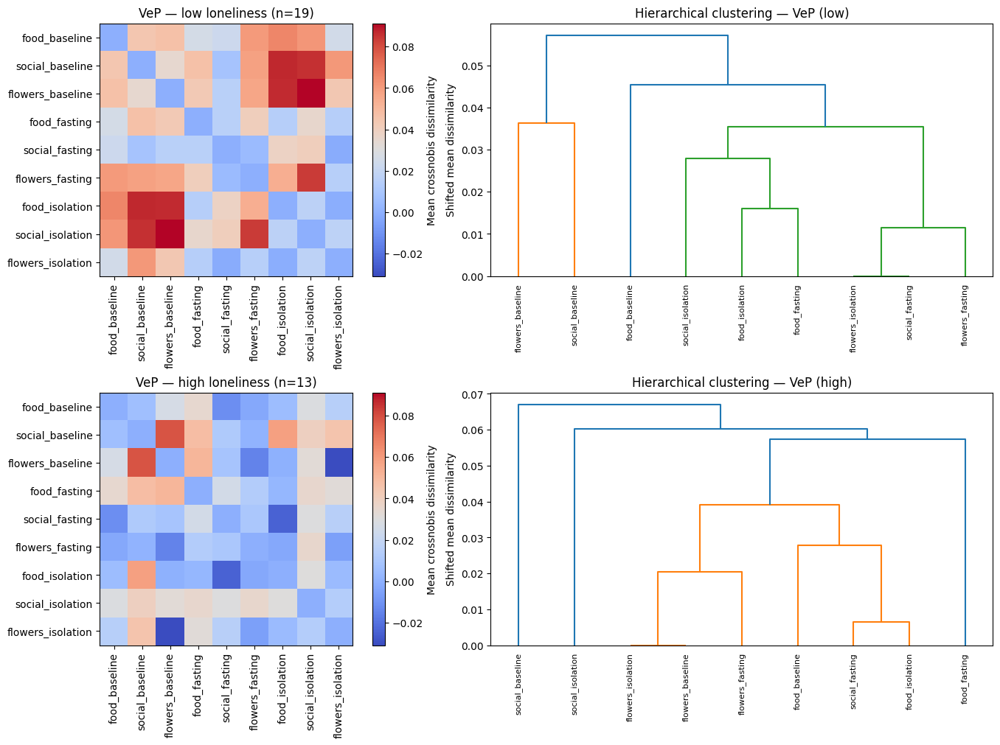

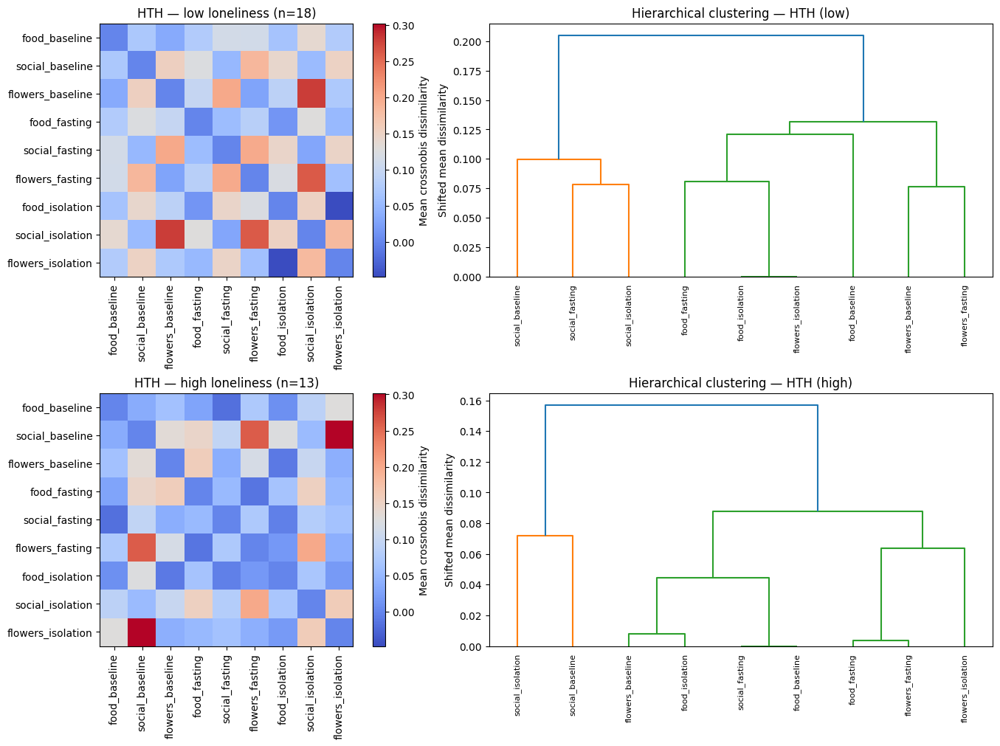

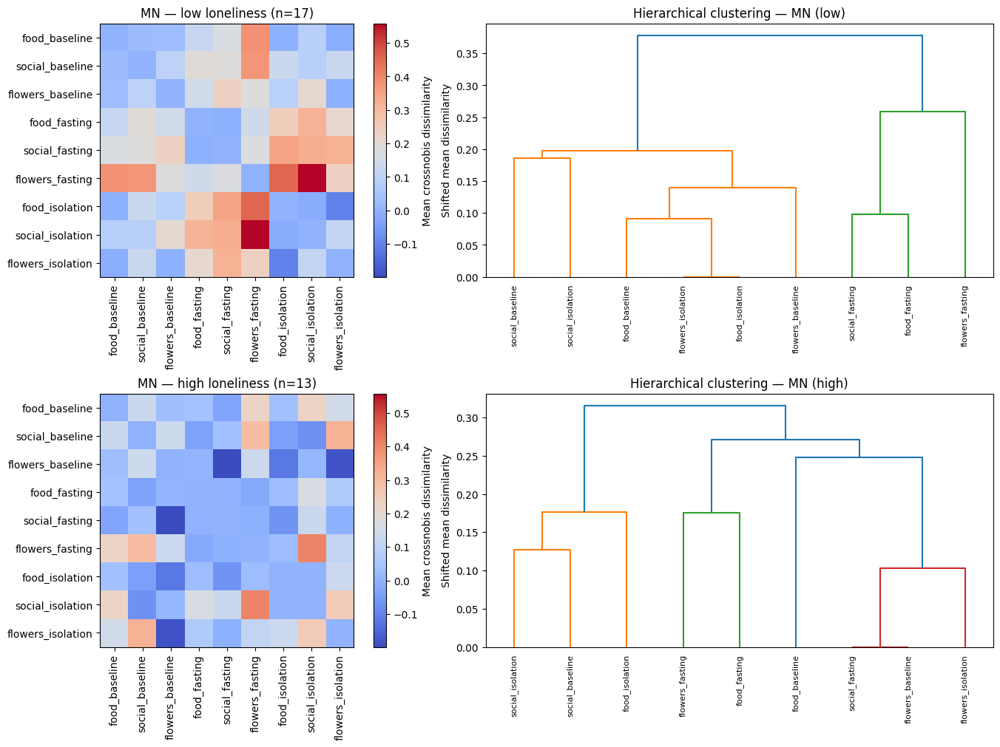

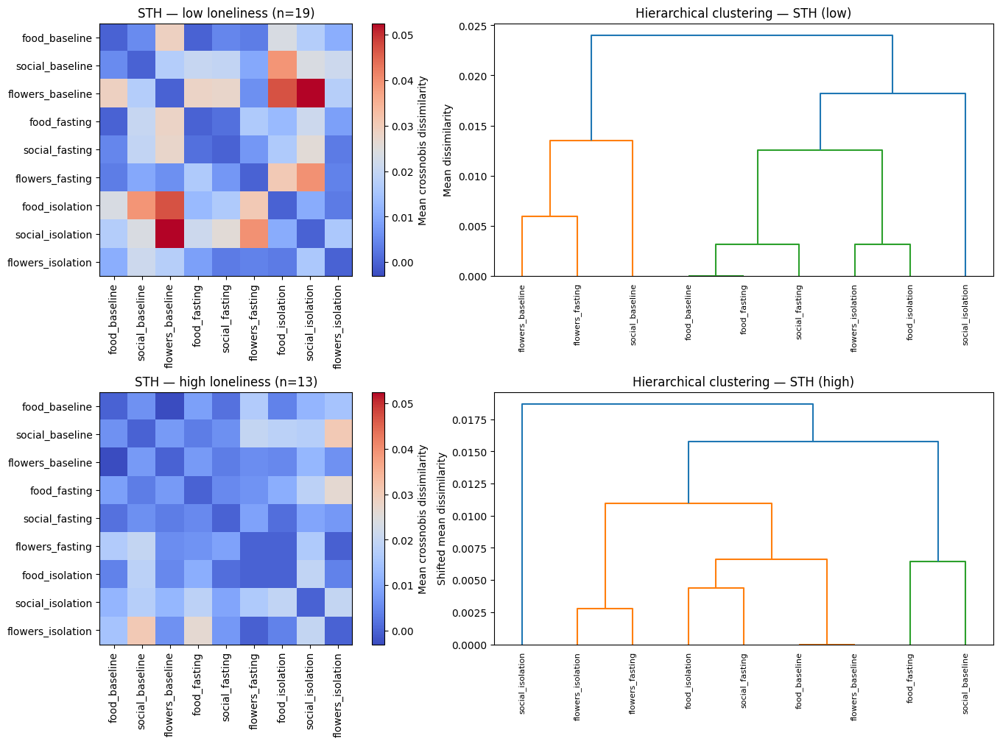

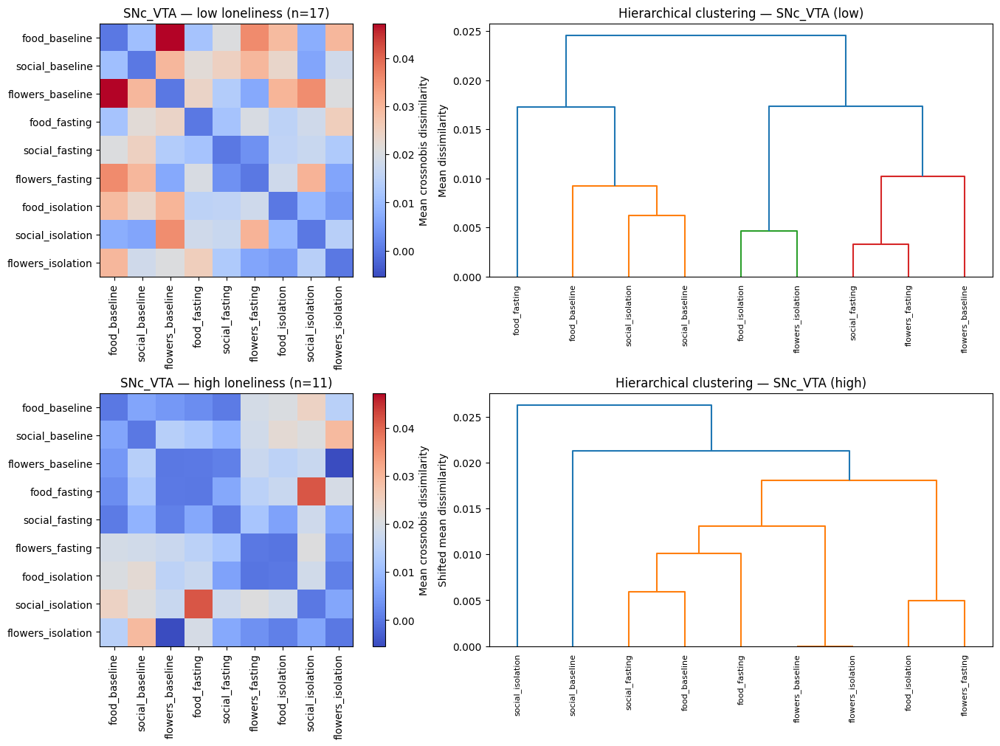

In [12]:

THRESH = 34
MIN_PER_GROUP = 5            # skip ROI/group combos with fewer participants

data = np.load("../results/rdms_thresh_80/crossnobis_rdms.npz")
all_rdms = data["rdms"]                          # [subject, roi, 9, 9]
subjects = list(data["subjects"])
rois = list(data["rois"])
contrasts = [str(c) for c in data["conditions"]]
n = len(contrasts)
upper = np.triu_indices(n, k=1)

# Loneliness group per subject ("sub-SAXSISO01" <-> "SAX_SISO_01")
beh = pd.read_csv("../dataframes/SISO_behavioral_data.csv")
beh["subject"] = "sub-" + beh["ID"].str.replace("_", "", regex=False)
group_of = np.where(beh["Loneliness_Score"] > THRESH, "high", "low")
group_of = dict(zip(beh["subject"], group_of))
missing = [s for s in subjects if s not in group_of]
if missing:
    raise ValueError(f"No loneliness score for: {missing}")
subject_group = np.array([group_of[s] for s in subjects])


def group_mean_rdm(stack):
    """Mean RDM, clustering tree, and shift for one [n_subjects, 9, 9] stack."""
    mean_rdm = stack.mean(axis=0)
    mean_rdm = (mean_rdm + mean_rdm.T) / 2
    np.fill_diagonal(mean_rdm, 0)

    # Crossnobis can be negative; shift so scipy linkage gets non-negative distances.
    shift = max(0.0, -float(mean_rdm[upper].min()))
    clustering = mean_rdm.copy()
    clustering[upper] += shift
    clustering[(upper[1], upper[0])] += shift
    tree = linkage(squareform(clustering, checks=True), method="average", optimal_ordering=True)
    return mean_rdm, tree, shift


results = {}

for roi_idx, roi_file in enumerate(rois):
    roi = roi_file.removesuffix(".nii")
    has_rdm = ~np.isnan(all_rdms[:, roi_idx]).all(axis=(1, 2))

    groups = {}
    for g in ("low", "high"):
        keep = has_rdm & (subject_group == g)
        if keep.sum() >= MIN_PER_GROUP:
            groups[g] = (keep, all_rdms[keep, roi_idx])
    if not groups:
        continue

    computed = {g: group_mean_rdm(stack) for g, (_, stack) in groups.items()}

    # Same colour scale for low and high so they are directly comparable
    vmin = min(m.min() for m, _, _ in computed.values())
    vmax = max(m.max() for m, _, _ in computed.values())

    fig, axes = plt.subplots(
        len(computed), 2, figsize=(14, 5 * len(computed)),
        gridspec_kw={"width_ratios": [1, 1.3]}, layout="constrained", squeeze=False,
    )

    for (g, (mean_rdm, tree, shift)), (ax_rdm, ax_tree) in zip(computed.items(), axes):
        keep = groups[g][0]
        image = ax_rdm.imshow(mean_rdm, cmap="coolwarm", vmin=vmin, vmax=vmax)  # fixed model order
        ax_rdm.set_xticks(range(n), contrasts, rotation=90)
        ax_rdm.set_yticks(range(n), contrasts)
        ax_rdm.set_title(f"{roi} — {g} loneliness (n={keep.sum()})")
        fig.colorbar(image, ax=ax_rdm, label="Mean crossnobis dissimilarity")

        dendrogram(tree, labels=contrasts, ax=ax_tree, leaf_rotation=90, leaf_font_size=8)
        ax_tree.set_title(f"Hierarchical clustering — {roi} ({g})")
        ax_tree.set_ylabel("Shifted mean dissimilarity" if shift else "Mean dissimilarity")

        results[(roi, g)] = {
            "mean_rdm": pd.DataFrame(mean_rdm, index=contrasts, columns=contrasts),
            "linkage": tree,
            "subjects": [s for s, k in zip(subjects, keep) if k],
            "distance_shift": shift,
        }

    plt.show()